# PiggyBack

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os, math, time, json, random
from pathlib import Path
from copy import deepcopy

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as tvm
import torchvision.transforms as T

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE)

Device: cuda


In [2]:
SEED = 67
N_TASKS = 10
CLASSES_PER_TASK = 10
ORDER_ID = 0

IMAGE_SIZE = 32
BATCH_SIZE = 128
NUM_WORKERS = 2

EPOCHS_PER_TASK = 30
MASK_LR = 2e-4     # Adam, real-valued masks
HEAD_LR = 1e-3     # Adam, task head
NORM_LR = 1e-3     # Adam, GroupNorm affine (per task)
MASK_INIT = 1e-2
THRESHOLD = 5e-3

PRETRAINED = True
GN_GROUPS = 32

DATA_DIR = next(Path("/kaggle/input").rglob("task_order.json")).parent
PLOT_DIR = Path("/kaggle/working/Plots")
PLOT_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

In [4]:
# Data Loading

CIFAR100_MEAN = (0.5071, 0.4865, 0.4409)
CIFAR100_STD  = (0.2673, 0.2564, 0.2762)

eval_tf = [T.ToTensor(), T.Normalize(CIFAR100_MEAN, CIFAR100_STD)]
train_tf = [T.RandomCrop(IMAGE_SIZE, padding=4), T.RandomHorizontalFlip()] + eval_tf
if IMAGE_SIZE != 32:
    train_tf, eval_tf = [T.Resize(IMAGE_SIZE)] + train_tf, [T.Resize(IMAGE_SIZE)] + eval_tf
transform_train, transform_eval = T.Compose(train_tf), T.Compose(eval_tf)

with open(DATA_DIR / "task_order.json") as f:
    meta = json.load(f)
ORDER = meta["task_orders"][ORDER_ID]

class TaskDataset(Dataset):
    def __init__(self, path, transform):
        data = np.load(path)
        self.images, self.labels, self.transform = data["images"], data["labels_local"], transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.transform(Image.fromarray(self.images[i])), int(self.labels[i])

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)

generator = torch.Generator()
generator.manual_seed(SEED)

def get_task_loaders(task_idx):
    loaders = {}
    for split in ("train", "valid", "test"):
        ds = TaskDataset(DATA_DIR / f"task-{task_idx + 1}" / split / "data.npz", transform_train if split == "train" else transform_eval)
        loaders[split] = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=(split == "train"), num_workers=NUM_WORKERS,
                                    pin_memory=True, worker_init_fn=seed_worker, generator=generator)
    return loaders

loaders = [get_task_loaders(ORDER[p]) for p in range(N_TASKS)]
print(f"Order {ORDER_ID} : {ORDER}")

Order 0 : [3, 8, 1, 4, 9, 0, 2, 6, 7, 5]


In [5]:
# GroupNorm helpers

def groups_for(num_channels, preferred=GN_GROUPS):
    if num_channels % preferred == 0:
        return preferred
    return max(math.gcd(preferred, num_channels), 1)

def bn_to_gn(module):
    for name, child in module.named_children():
        if isinstance(child, nn.BatchNorm2d):
            setattr(module, name, nn.GroupNorm(groups_for(child.num_features), child.num_features))
        else:
            bn_to_gn(child)
    return module

def norm_parameters(model):
    for name, m in model.named_modules():
        if isinstance(m, nn.GroupNorm):
            for pname, p in m.named_parameters(recurse=False):
                yield f"{name}.{pname}", p

class Binarizer(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, threshold):
        return (x > threshold).to(x.dtype)

    @staticmethod
    def backward(ctx, grad_output):
        return grad_output, None

# Metrics

def accuracy(logits, y):
    return (logits.argmax(dim=1) == y).float().mean().item()

def empty_accuracy_matrix(n_tasks):
    return np.full((n_tasks, n_tasks), np.nan, dtype=float)

def set_accuracy(R, after_task, eval_task, acc):
    R[after_task, eval_task] = acc

def forgetting(R):
    n = R.shape[0]
    per_task = np.array([R[i, i] - R[n - 1, i] for i in range(n - 1)], dtype=float)
    return {"per_task": per_task.tolist(), "average": float(np.nanmean(per_task)) if per_task.size else 0.0}

def final_average_accuracy(R):
    return float(np.nanmean(R[R.shape[0] - 1]))

def mask_sparsity(masks):
    """Fraction of conv weights a task's binary mask switches off."""
    ones = sum(int(m.sum()) for m in masks.values())
    total = sum(m.numel() for m in masks.values())
    return 1.0 - ones / total

def storage_stats(store):
    """Bytes per task = bit-packed binary mask (1 bit per conv weight) + fp32 head + fp32 GroupNorm affine.
    The frozen pretrained backbone is stored once (fp32)."""
    n_conv = sum(m.numel() for m in next(iter(store.masks.values())).values())
    per_task = {}
    for t, masks in store.masks.items():
        mask_bytes = n_conv / 8
        extra_bytes = 4 * (sum(v.numel() for v in store.heads[t].values()) + sum(v.numel() for v in store.norms[t].values()))
        per_task[t] = {"sparsity": mask_sparsity(masks), "mask_bytes": mask_bytes, "extra_bytes": extra_bytes, "total_bytes": mask_bytes + extra_bytes}
    backbone_bytes = 4 * n_conv
    return {
        "per_task": per_task,
        "backbone_bytes": backbone_bytes,
        "total_bytes": backbone_bytes + sum(v["total_bytes"] for v in per_task.values()),
        "separate_models_bytes": sum(backbone_bytes + v["extra_bytes"] for v in per_task.values()),
    }

## Model definition

ResNet-50 (GroupNorm) backbone whose every conv is a `MaskedConv2d` (frozen pretrained weights × learnable binary mask), one head per task, and a `TaskStore` that keeps each task's binary masks, head and GroupNorm affine.

In [6]:
def build_backbone(pretrained=PRETRAINED):
    weights = tvm.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
    model = tvm.resnet50(weights=weights)
    model = bn_to_gn(model)
    for m in model.modules():
        if isinstance(m, tvm.resnet.Bottleneck):
            nn.init.zeros_(m.bn3.weight)
    feature_dim = model.fc.in_features
    model.fc = nn.Identity()
    model.feature_dim = feature_dim
    return model

class MaskedConv2d(nn.Module):
    """Conv2d with a frozen weight and a learnable binary mask (PiggyBack).
    weight     : frozen buffer (pretrained conv weight, never updated)
    mask_real  : trainable real-valued mask; the binary mask is (mask_real > threshold),
                 gradients pass through the threshold unchanged (straight-through)
    stored_mask: when set, forward uses this fixed binary mask instead (evaluating a stored task)"""
    def __init__(self, conv, mask_init=MASK_INIT, threshold=THRESHOLD):
        super().__init__()
        self.stride, self.padding = conv.stride, conv.padding
        self.dilation, self.groups = conv.dilation, conv.groups
        self.mask_init, self.threshold = mask_init, threshold
        self.register_buffer("weight", conv.weight.detach().clone())
        self.mask_real = nn.Parameter(torch.full_like(self.weight, mask_init))
        self.stored_mask = None

    def reset_mask(self):
        self.stored_mask = None
        with torch.no_grad():
            self.mask_real.fill_(self.mask_init)

    def binary_mask(self):
        return self.mask_real.detach() > self.threshold

    def set_stored(self, mask):
        self.stored_mask = mask.to(self.weight.device, self.weight.dtype)

    def forward(self, x):
        mask = self.stored_mask if self.stored_mask is not None else Binarizer.apply(self.mask_real, self.threshold)
        return F.conv2d(x, self.weight * mask, None, self.stride, self.padding, self.dilation, self.groups)

def convert_convs(module):
    """Replace every nn.Conv2d in the network by a MaskedConv2d."""
    for name, child in module.named_children():
        if isinstance(child, nn.Conv2d):
            setattr(module, name, MaskedConv2d(child))
        else:
            convert_convs(child)
    return module

def masked_convs(model):
    for name, m in model.named_modules():
        if isinstance(m, MaskedConv2d):
            yield name, m

def backbone_fingerprint(model):
    """Sum of all frozen conv weights — must be identical before and after training."""
    return sum(m.weight.double().sum().item() for _, m in masked_convs(model))

class PiggyBackResNet(nn.Module):
    """Masked ResNet-50 (GroupNorm) backbone + a classification head. The head is re-initialised
    for every task and its trained state is stored per task."""
    def __init__(self, num_classes=CLASSES_PER_TASK):
        super().__init__()
        self.backbone = convert_convs(build_backbone())
        self.head = nn.Linear(self.backbone.feature_dim, num_classes)

    def forward(self, x):
        return self.head(self.backbone(x))

class TaskStore:
    """Everything that is specific to a task (the frozen backbone is shared):
    masks[t] : {conv name: bool tensor}   binary mask over the conv weights
    heads[t] : head state_dict
    norms[t] : {GroupNorm param name: tensor}   GroupNorm affine"""
    def __init__(self, model):
        self.model = model
        self.masks, self.heads, self.norms = {}, {}, {}
        self.init_norms = {n: p.detach().clone() for n, p in norm_parameters(model)}

    def _set_norms(self, state):
        with torch.no_grad():
            for n, p in norm_parameters(self.model):
                p.copy_(state[n])

    def new_task(self):
        """Start a task from scratch: all-ones mask (= full pretrained backbone), fresh head,
        GroupNorm affine back to its initial state."""
        for _, m in masked_convs(self.model):
            m.reset_mask()
        self.model.head.reset_parameters()
        self._set_norms(self.init_norms)

    def save(self, task_id):
        """Binarise the learned masks and keep them with the task's head and GroupNorm affine."""
        self.masks[task_id] = {n: m.binary_mask().cpu() for n, m in masked_convs(self.model)}
        self.heads[task_id] = deepcopy(self.model.head.state_dict())
        self.norms[task_id] = {n: p.detach().clone() for n, p in norm_parameters(self.model)}

    def load_task(self, task_id):
        """Swap in task `task_id`'s masks, head and GroupNorm affine."""
        for n, m in masked_convs(self.model):
            m.set_stored(self.masks[task_id][n])
        self.model.head.load_state_dict(self.heads[task_id])
        self._set_norms(self.norms[task_id])

## Model summary

In [11]:
model = PiggyBackResNet().to(DEVICE)
store = TaskStore(model)
FINGERPRINT = backbone_fingerprint(model)

n_conv = sum(m.weight.numel() for _, m in masked_convs(model))
n_norm = sum(p.numel() for _, p in norm_parameters(model))
n_head = sum(p.numel() for p in model.head.parameters())

print(f"Frozen Backbone Weights  : {n_conv:,}")
print(f"Masked Conv Layers       : {sum(1 for _ in masked_convs(model))}")
print(f"Mask Parameters per Task : {n_conv:,}  (stored as {n_conv / 8 / 2**20:.2f} MiB of bits)")
print(f"GroupNorm Affine per Task: {n_norm:,}")
print(f"Head Parameters per Task : {n_head:,}")
print(f"Trainable per Task       : {n_conv + n_norm + n_head:,}")

Frozen Backbone Weights  : 23,454,912
Masked Conv Layers       : 53
Mask Parameters per Task : 23,454,912  (stored as 2.80 MiB of bits)
GroupNorm Affine per Task: 53,120
Head Parameters per Task : 20,490
Trainable per Task       : 23,528,522


## Training Definition


In [12]:
criterion = nn.CrossEntropyLoss()

def run_epoch(loader, optimizer=None, scaler=None, train=True):
    model.train() if train else model.eval()
    total_loss, total_acc, n = 0.0, 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(train):
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
        bs = y.size(0)
        total_loss += loss.item() * bs
        total_acc += accuracy(out, y) * bs
        n += bs
    return total_loss / n, total_acc / n

def build_optimizer():
    groups = [
        {"params": [m.mask_real for _, m in masked_convs(model)], "lr": MASK_LR},
        {"params": [p for _, p in norm_parameters(model)], "lr": NORM_LR},
        {"params": list(model.head.parameters()), "lr": HEAD_LR},]
    return torch.optim.Adam(groups, weight_decay=0)

def trainable_state():
    return {n: p.detach().clone() for n, p in model.named_parameters()}

def load_trainable_state(state):
    with torch.no_grad():
        for n, p in model.named_parameters():
            p.copy_(state[n])

def fit(task_loaders, epochs):
    """Train the current task's masks, GroupNorm affine and head for `epochs`. The best-validation
    epoch is kept in memory and reloaded at the end."""
    optimizer = build_optimizer()
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    history = {'epoch': [], 'train_loss': [], 'validation_loss': [], 'train_accuracy': [], 'validation_accuracy': [], 'lr': []}
    best_val_acc, best_epoch, best_state = -1.0, 0, None
    
    hdr = (f"{'Epoch':>6}  {'T-Loss':>8}  {'V-Loss':>8} {'T-Acc':>8}  {'V-Acc':>8}{'LR':>10}     {'Time':>7}")
    print(hdr)
    print('─' * (len(hdr)+2))

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        cur_lr = optimizer.param_groups[0]["lr"]
        tr_loss, tr_acc = run_epoch(task_loaders["train"], optimizer, scaler, train=True)
        va_loss, va_acc = run_epoch(task_loaders["valid"], train=False)
        scheduler.step()

        for k, v in zip(history, [epoch, tr_loss, va_loss, tr_acc, va_acc, cur_lr]):
            history[k].append(v)

        saved_flag = ''
        if va_acc > best_val_acc:
            best_val_acc, best_epoch, best_state = va_acc, epoch, trainable_state()
            saved_flag = ' ★'

        print(f'{epoch:>6}  {tr_loss:>8.4f}  {va_loss:>8.4f}  '
              f'{tr_acc:>8.4f}  {va_acc:>8.4f}  {cur_lr:>10.2e}  {time.time() - t0:>6.1f}s{saved_flag}')

    print('─' * len(hdr))
    load_trainable_state(best_state)
    print(f'best val acc: {best_val_acc:.4f} @ epoch {best_epoch} (reloaded)')
    return history

## Main Training Loop

In [ ]:
R = empty_accuracy_matrix(N_TASKS)
all_histories = {}

for task_id in range(1, N_TASKS + 1):
    task_loaders = loaders[task_id - 1]
    task_idx = ORDER[task_id - 1]

    print(f"\n==== Task {task_id}/{N_TASKS}  (task-{task_idx + 1}, classes {meta['class_to_task'][task_idx]}) ====")
    store.new_task()
    all_histories[task_id] = fit(task_loaders, EPOCHS_PER_TASK)
    store.save(task_id)

    # test accuracy of every task learned so far; the backbone never changes, so this should show no forgetting
    for j in range(1, task_id + 1):
        store.load_task(j)
        _, acc_j = run_epoch(loaders[j - 1]["test"], train=False)
        set_accuracy(R, task_id - 1, j - 1, acc_j)
    print(f"Task {task_id} done | test acc on tasks 1..{task_id}: {np.round(R[task_id - 1, :task_id], 4).tolist()}"
          f" | mask sparsity {mask_sparsity(store.masks[task_id]):.1%}")


==== Task 1/10  (task-4, classes [1, 6, 8, 20, 37, 38, 44, 62, 80, 84]) ====
 Epoch    T-Loss    V-Loss    T-Acc     V-Acc        LR        Time
─────────────────────────────────────────────────────────────────────
     1    2.1535    2.0380    0.2080    0.2900    2.00e-04     5.2s ★
     2    1.8651    1.8957    0.3300    0.3320    1.99e-04     2.4s ★
     3    1.6805    1.7011    0.4016    0.4060    1.98e-04     2.7s ★
     4    1.5273    1.6066    0.4507    0.4300    1.95e-04     2.3s ★
     5    1.3701    1.3688    0.5049    0.5040    1.91e-04     2.3s ★
     6    1.3007    1.4091    0.5391    0.5020    1.87e-04     2.2s
     7    1.2271    1.2840    0.5580    0.5300    1.81e-04     2.3s ★
     8    1.1657    1.2623    0.5762    0.5540    1.74e-04     2.2s ★
     9    1.0597    1.2256    0.6211    0.5580    1.67e-04     2.2s ★
    10    1.0938    1.2036    0.6084    0.5880    1.59e-04     2.3s ★
    11    1.0349    1.0720    0.6242    0.5940    1.50e-04     2.3s ★
    12    0.9782

In [14]:
# Evaluation summary

final_acc = final_average_accuracy(R)
forget = forgetting(R)
stor = storage_stats(store)

drift = max(abs(R[N_TASKS - 1, i] - R[i, i]) for i in range(N_TASKS - 1))
unchanged = drift < 1e-9 and backbone_fingerprint(model) == FINGERPRINT
mib = 2 ** 20
avg_task = np.mean([v["total_bytes"] for v in stor["per_task"].values()])

print(f"Final Average Accuracy across All {N_TASKS} Tasks : {final_acc:.4f}")
print(f"Average Forgetting                                : {forget['average']:.4f}")
print(f"Per-task Forgetting                               : {[round(v, 4) for v in forget['per_task']]}")
print(f"Backbone never changed                            : {'yes' if unchanged else 'NO'}  (max |R[last, i] - R[i, i]| = {drift:.4f})")
print(f"Storage per task (mask + head + GroupNorm)        : {avg_task / mib:.2f} MiB  ({avg_task / stor['backbone_bytes']:.1%} of the fp32 backbone)")
print(f"Total Storage (1 backbone + {N_TASKS} tasks)      : {stor['total_bytes'] / mib:.1f} MiB  ({stor['total_bytes'] / stor['separate_models_bytes']:.1%} of {N_TASKS} separate fp32 models)")
print(f"Mask Sparsity per task                            : {[round(stor['per_task'][t]['sparsity'], 4) for t in range(1, N_TASKS + 1)]}")

Final Average Accuracy across All 10 Tasks : 0.7700
Average Forgetting                                : 0.0000
Per-task Forgetting                               : [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Backbone never changed                            : yes  (max |R[last, i] - R[i, i]| = 0.0000)
Storage per task (mask + head + GroupNorm)        : 3.08 MiB  (3.4% of the fp32 backbone)
Total Storage (1 backbone + 10 tasks)      : 120.2 MiB  (13.4% of 10 separate fp32 models)
Mask Sparsity per task                            : [0.0898, 0.0859, 0.0906, 0.0899, 0.0918, 0.0905, 0.0896, 0.0922, 0.0917, 0.0905]


## Plots

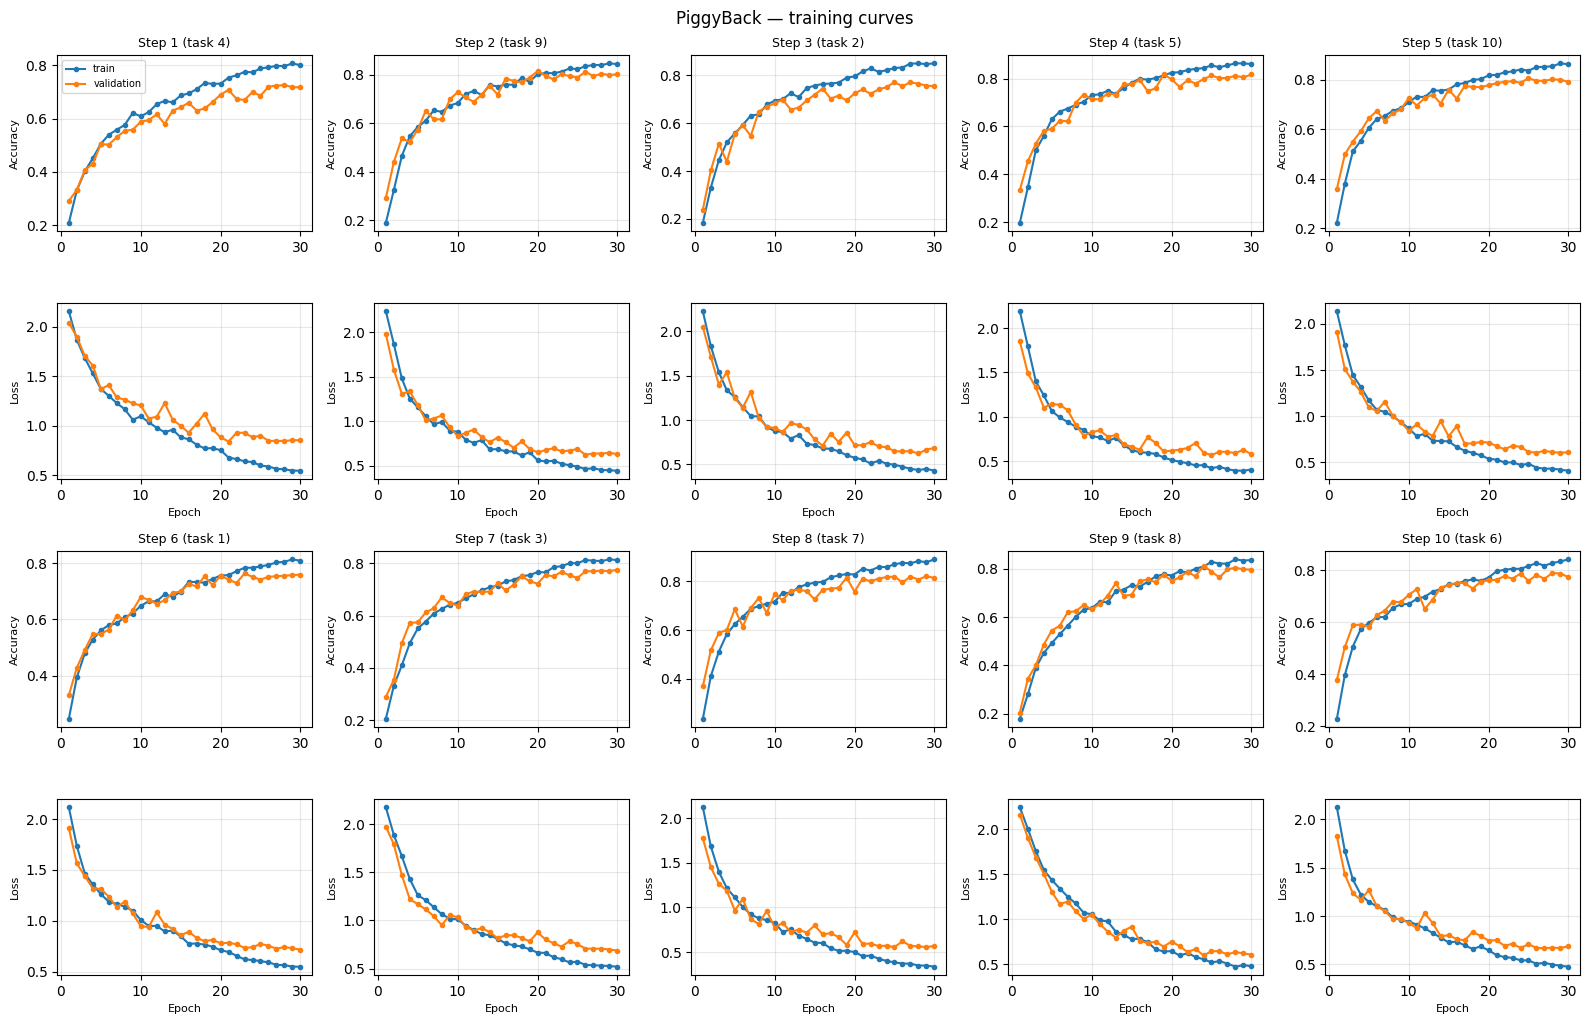

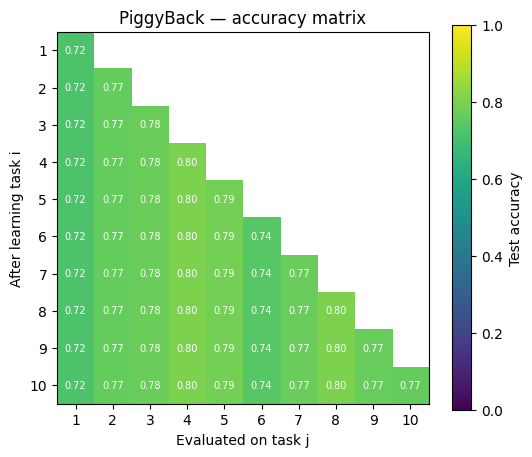

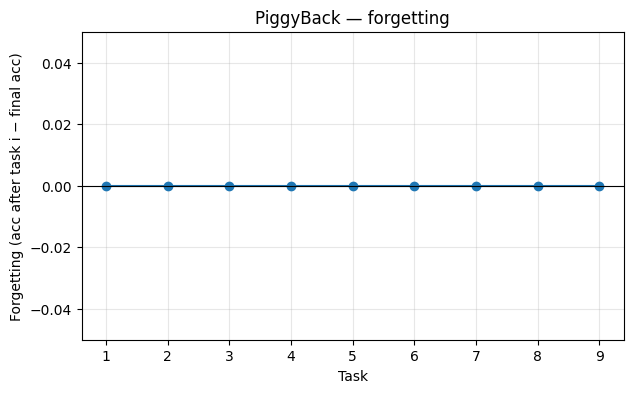

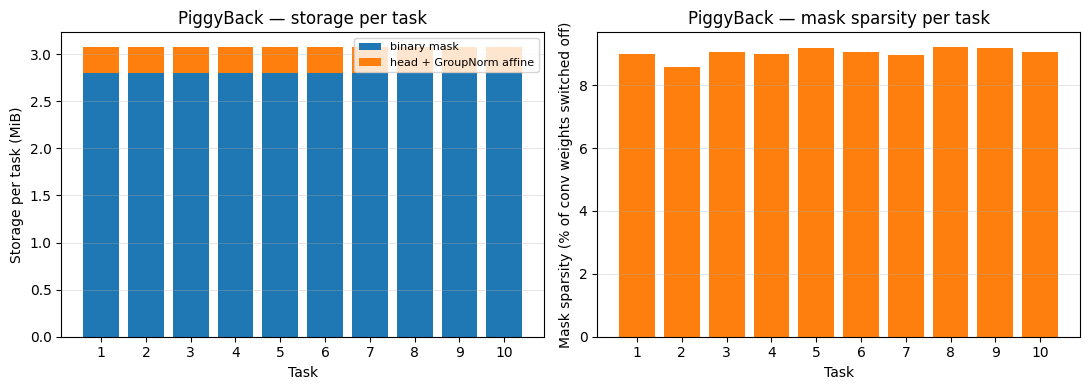

In [10]:
def plot_training_curves(histories, save_path):
    n_cols = 5
    n_blocks = math.ceil(len(histories) / n_cols)
    fig, axes = plt.subplots(2 * n_blocks, n_cols, figsize=(3.2 * n_cols, 2.6 * 2 * n_blocks), squeeze=False)
    for t, h in histories.items():
        r, c = divmod(t - 1, n_cols)
        for row, metric in ((2 * r, "accuracy"), (2 * r + 1, "loss")):
            ax = axes[row, c]
            ax.plot(h["epoch"], h[f"train_{metric}"], marker="o", ms=3, label="train")
            ax.plot(h["epoch"], h[f"validation_{metric}"], marker="o", ms=3, label="validation")
            ax.set_ylabel(metric.capitalize(), fontsize=8); ax.grid(alpha=0.3)
            if row == 2 * r:
                ax.set_title(f"Step {t} (task {ORDER[t - 1] + 1})", fontsize=9)
            else:
                ax.set_xlabel("Epoch", fontsize=8)
    axes[0, 0].legend(fontsize=7)
    for ax in axes.flat:
        if not ax.has_data():
            ax.axis("off")
    fig.suptitle("PiggyBack — training curves")
    fig.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_accuracy_matrix(R, save_path):
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(R, vmin=0, vmax=1, cmap="viridis")
    ax.set_xlabel("Evaluated on task j"); ax.set_ylabel("After learning task i")
    ax.set_xticks(range(R.shape[1])); ax.set_yticks(range(R.shape[0]))
    ax.set_xticklabels(range(1, R.shape[1] + 1)); ax.set_yticklabels(range(1, R.shape[0] + 1))
    for i in range(R.shape[0]):
        for j in range(R.shape[1]):
            if not np.isnan(R[i, j]):
                ax.text(j, i, f"{R[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
    fig.colorbar(im, ax=ax, label="Test accuracy"); ax.set_title("PiggyBack — accuracy matrix")
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_forgetting(per_task, save_path):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(range(1, len(per_task) + 1), per_task, marker="o")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_ylim(min(-0.05, min(per_task) - 0.01), max(0.05, max(per_task) + 0.01))
    ax.set_xlabel("Task"); ax.set_ylabel("Forgetting (acc after task i − final acc)")
    ax.set_title("PiggyBack — forgetting"); ax.grid(alpha=0.3)
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_capacity(stor, save_path):
    tasks = sorted(stor["per_task"])
    mask_mib = [stor["per_task"][t]["mask_bytes"] / 2**20 for t in tasks]
    extra_mib = [stor["per_task"][t]["extra_bytes"] / 2**20 for t in tasks]
    sparsity = [100 * stor["per_task"][t]["sparsity"] for t in tasks]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    ax1.bar(tasks, mask_mib, label="binary mask")
    ax1.bar(tasks, extra_mib, bottom=mask_mib, label="head + GroupNorm affine")
    ax1.set_xticks(tasks); ax1.set_xlabel("Task"); ax1.set_ylabel("Storage per task (MiB)")
    ax1.set_title("PiggyBack — storage per task"); ax1.grid(alpha=0.3, axis="y"); ax1.legend(fontsize=8)

    ax2.bar(tasks, sparsity, color="tab:orange")
    ax2.set_xticks(tasks); ax2.set_xlabel("Task"); ax2.set_ylabel("Mask sparsity (% of conv weights switched off)")
    ax2.set_title("PiggyBack — mask sparsity per task"); ax2.grid(alpha=0.3, axis="y")
    fig.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_training_curves(all_histories, PLOT_DIR / "piggyback_training_curves.png")
plot_accuracy_matrix(R, PLOT_DIR / "piggyback_accuracy_matrix.png")
plot_forgetting(forget["per_task"], PLOT_DIR / "piggyback_forgetting.png")
plot_capacity(stor, PLOT_DIR / "piggyback_capacity.png")